# Приотизация обращений 

Задача: ранжирование обращений (лидов) по вероятности успешного целевого действия в течение 5 дней после назначения на колл-центр. Метрика - Daily Average Precision: Average Precision по каждой дате назначения, усредненный по дням.

### Импорты и константы

In [67]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier, EFeaturesSelectionAlgorithm, EShapCalcType

In [2]:
DATA_DIR = Path("data")
TARGET = "target"

NON_FEATURE_COLUMNS = {"lead_id", "user_id", "assignment_ts", "assignment_date", TARGET}

WINDOWS = ["1d", "3d", "7d", "14d", "30d", "90d"]
ACTIVITY_COUNTERS = [
    "item_views", "item_favorites", "detail_expands", "photo_swipes",
    "seller_page_views", "search_views", "query_refinements",
    "similar_item_clicks", "saved_search_matches", "user_contacts",
    "chat_opens", "call_clicks", "active_days_auto",
]

N_FOLDS = 4
VALID_DAYS = 2

RANDOM_STATE = 42

### Загрузка данных

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["assignment_ts"])
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["assignment_ts"])
events = pd.read_csv(DATA_DIR / "events.csv", parse_dates=["event_ts"])
base_rate = train[TARGET].mean()

print("train:", train.shape)
print("test:", test.shape)
print("events:", events.shape)
print(f"Доля успеха в train: {base_rate:.4f}")

train: (13694, 119)
test: (4306, 118)
events: (254705, 7)
Доля успеха в train: 0.2075


In [4]:
train.head(5)

,lead_id,user_id,assignment_ts,assignment_date,lead_source,call_center,region,car_segment,lead_channel,user_tenure_bucket,...,leadgen_prev_positive_14d,leadgen_prev_positive_30d,leadgen_prev_positive_90d,active_days_auto_1d,active_days_auto_3d,active_days_auto_7d,active_days_auto_14d,active_days_auto_30d,active_days_auto_90d,target
0,lead_f57db09ab39ae3e7,user_0000001,2026-04-22 11:56:00,2026-04-22,CRM,external,west,budget,retargeting,warm,...,0.0,0.0,0.0,0.0,0.0,0.0,4.0,9.0,26.0,0
1,lead_a6184b8a8165a27b,user_0000002,2026-04-07 14:49:00,2026-04-07,CRM,voxys,north,standard,partner,warm,...,0.0,NaN,1.0,0.0,0.0,0.0,NaN,4.0,5.0,0
2,lead_229c2a117dbac203,user_0000003,2026-04-12 17:01:00,2026-04-12,Perf,external,north,budget,retargeting,new,...,0.0,0.0,NaN,2.0,4.0,1.0,10.0,12.0,52.0,0
3,lead_16b19e58042ef905,user_0000005,2026-04-13 21:39:00,2026-04-13,Model,voxys,east,premium,partner,warm,...,0.0,1.0,0.0,0.0,1.0,0.0,3.0,2.0,NaN,1
4,lead_734c227324978a36,user_0000006,2026-04-12 18:01:00,2026-04-12,CRM,voxys,central,budget,retargeting,warm,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,9.0,0


In [5]:
print(train.dtypes.to_string())

lead_id                                 str
user_id                                 str
assignment_ts                datetime64[us]
assignment_date                         str
lead_source                             str
call_center                             str
region                                  str
car_segment                             str
lead_channel                            str
user_tenure_bucket                      str
price_bucket                            str
assignment_hour                     float64
assignment_weekday                  float64
is_weekend                          float64
user_active_days_30d                float64
user_age_days                       float64
prior_assignments_30d               float64
seller_inventory_count              float64
seller_response_rate_30d            float64
item_price_log                      float64
car_age_years                       float64
mileage_km_log                      float64
item_views_1d                   

In [6]:
test.head(5)

,lead_id,user_id,assignment_ts,assignment_date,lead_source,call_center,region,car_segment,lead_channel,user_tenure_bucket,...,leadgen_prev_positive_7d,leadgen_prev_positive_14d,leadgen_prev_positive_30d,leadgen_prev_positive_90d,active_days_auto_1d,active_days_auto_3d,active_days_auto_7d,active_days_auto_14d,active_days_auto_30d,active_days_auto_90d
0,lead_97e409eb8f8c8246,user_0000000,2026-04-27 13:09:00,2026-04-27,CRM,voxys,north,commercial,retargeting,new,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,2.0,9.0,34.0
1,lead_55310edb4489f9e9,user_0000004,2026-04-24 14:48:00,2026-04-24,Model,voxys,east,standard,retargeting,warm,...,0.0,0.0,1.0,0.0,0.0,0.0,2.0,1.0,6.0,12.0
2,lead_e7f653a2c6a7eee8,user_0000019,2026-04-27 16:00:00,2026-04-27,Model,voxys,west,commercial,app,new,...,0.0,0.0,1.0,0.0,1.0,3.0,4.0,3.0,2.0,21.0
3,lead_22f8e1cfc487ac20,user_0000021,2026-04-27 11:56:00,2026-04-27,Model,external,north,commercial,web,loyal,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,3.0,11.0
4,lead_48b638b839abfac3,user_0000023,2026-04-26 10:13:00,2026-04-26,CRM,voxys,east,standard,app,warm,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,2.0,4.0,9.0


In [7]:
print(test.dtypes.to_string())

lead_id                                 str
user_id                                 str
assignment_ts                datetime64[us]
assignment_date                         str
lead_source                             str
call_center                             str
region                                  str
car_segment                             str
lead_channel                            str
user_tenure_bucket                      str
price_bucket                            str
assignment_hour                     float64
assignment_weekday                  float64
is_weekend                          float64
user_active_days_30d                float64
user_age_days                       float64
prior_assignments_30d               float64
seller_inventory_count              float64
seller_response_rate_30d            float64
item_price_log                      float64
car_age_years                       float64
mileage_km_log                      float64
item_views_1d                   

In [8]:
events.head(5)

,lead_id,user_id,event_ts,event_type,item_price_log,src_slot,ctx_seq
0,lead_00025e9610a0d90d,user_0016636,2026-03-27 06:41:00,chat_open,13.303438,19.0,c02
1,lead_00025e9610a0d90d,user_0016636,2026-03-31 09:10:00,item_view,13.322707,6.0,c06
2,lead_00025e9610a0d90d,user_0016636,2026-04-02 22:04:00,item_view,13.395721,10.0,c06
3,lead_00025e9610a0d90d,user_0016636,2026-04-04 09:19:00,search,13.395955,10.0,c04
4,lead_00025e9610a0d90d,user_0016636,2026-04-07 12:36:00,item_view,13.472769,2.0,c02


In [9]:
events.info()

<class 'pandas.DataFrame'>
RangeIndex: 254705 entries, 0 to 254704
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   lead_id         254705 non-null  str           
 1   user_id         254705 non-null  str           
 2   event_ts        254705 non-null  datetime64[us]
 3   event_type      254705 non-null  str           
 4   item_price_log  254705 non-null  float64       
 5   src_slot        254705 non-null  float64       
 6   ctx_seq         254705 non-null  str           
dtypes: datetime64[us](1), float64(2), str(4)
memory usage: 13.6 MB


In [10]:
feature_columns = [c for c in train.columns if c not in NON_FEATURE_COLUMNS]
categorical_features = [c for c in feature_columns if train[c].dtype == "str"]
numeric_features = [c for c in feature_columns if c not in categorical_features]

print(f"Признаков: {len(feature_columns)}, числовых: {len(numeric_features)}, "
      f"категориальных: {len(categorical_features)}")
print("Категориальные:", categorical_features)

Признаков: 114, числовых: 107, категориальных: 7
Категориальные: ['lead_source', 'call_center', 'region', 'car_segment', 'lead_channel', 'user_tenure_bucket', 'price_bucket']


## EDA

### 1. Временная структура 

Так как каждая строка в данных это обращение в конкретный день, посмотрим как периоды train и test расположены по времени, есть ли пересечения.

In [11]:
temporal_structure = pd.DataFrame({
    "min_date": [train["assignment_date"].min(), test["assignment_date"].min()],
    "max_date": [train["assignment_date"].max(), test["assignment_date"].max()],
    "n_days": [train["assignment_date"].nunique(), test["assignment_date"].nunique()],
    "n_rows": [len(train), len(test)],
}, index=["train", "test"])
print(temporal_structure)
intersection_date = set(train["assignment_date"]) & set(test["assignment_date"])
print(f"Пересекающихся дат: {len(intersection_date)}")

         min_date    max_date  n_days  n_rows
train  2026-04-07  2026-04-22      16   13694
test   2026-04-23  2026-04-27       5    4306
Пересекающихся дат: 0


**Вывод** Train и Test не пересекаются по времени, test идет сразу после train. В качестве схемы валидации будет использоваться временная кросс-валидация с расширяющимся окном.

Все решения, используещие таргет, будем принимать только по обучающим дням первого фолда.

In [12]:
days = np.sort(train["assignment_date"].unique())
cv_days = days[-N_FOLDS * VALID_DAYS:]
is_early = train["assignment_date"] < cv_days[0]
early = train[is_early]

print(f"Дни валидации time_cv: {cv_days[0]} - {cv_days[-1]} ({N_FOLDS} фолда по {VALID_DAYS} дня)")
print(f"Дни до первого фолда: {early['assignment_date'].min()} - {early['assignment_date'].max()}, "
      f"лидов: {len(early)}, доля успеха: {early[TARGET].mean():.4f}")

Дни валидации time_cv: 2026-04-15 - 2026-04-22 (4 фолда по 2 дня)
Дни до первого фолда: 2026-04-07 - 2026-04-14, лидов: 6743, доля успеха: 0.2087


### 2. Баланс классов 

Daily AP (метрика по условию задачи) усредняет Average Precision по дням, поэтому посмотрим на баланс классов по дням.

In [13]:
daily = train.groupby("assignment_date")[TARGET].agg(n_leads="size", n_pos="sum", positive_rate="mean", ).round(4)
daily

,n_leads,n_pos,positive_rate
assignment_date,,,
2026-04-07,873,195,0.2234
2026-04-08,832,174,0.2091
2026-04-09,859,177,0.2061
2026-04-10,830,183,0.2205
2026-04-11,861,175,0.2033
2026-04-12,855,174,0.2035
2026-04-13,791,163,0.2061
2026-04-14,842,166,0.1971
2026-04-15,899,179,0.1991


In [14]:
overall_rate = train[TARGET].mean()
d_pr = daily.positive_rate
print(f"Общий positive_rate: {overall_rate:.4f}")
print(f"positive_rate по дням: min={d_pr.min():.4f}, max={d_pr.max():.4f}, std={d_pr.std():.4f}")
print(f"Дней с одним классом: {((d_pr == 0) | (d_pr == 1)).sum()}")

Общий positive_rate: 0.2075
positive_rate по дням: min=0.1916, max=0.2354, std=0.0118
Дней с одним классом: 0


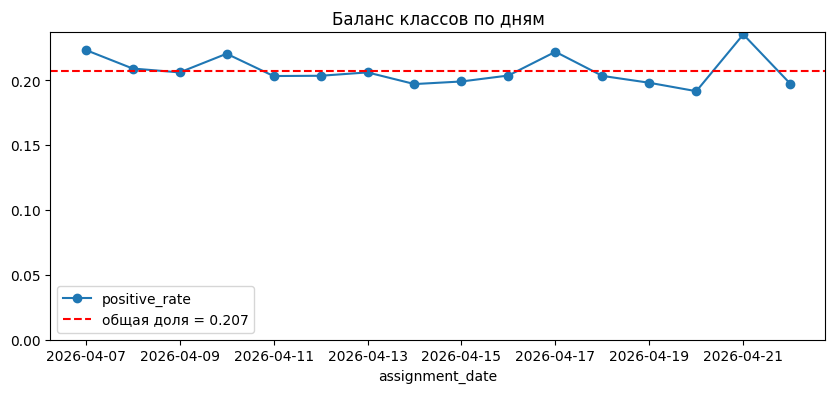

In [15]:
ax = daily["positive_rate"].plot(marker="o", figsize=(10, 4), ylim=(0, None), title="Баланс классов по дням")
ax.axhline(overall_rate, color="red", linestyle="--", label=f"общая доля = {overall_rate:.3f}")
ax.legend()
plt.show()

**Вывод:** Доля успешных лидов стабильна по дням, 0.19-0.24, mean = 0.208, std = 0.012, без трендов, дней с одним классом нет. Daily AP будет считаться без искажений от вырожденных дней и перекоса размеров. Балансировка классов не нужна: дисбаланс умеренный, метрика ранжирующая. Явных временных сдвигов нет.

### 3. Пересечение пользователей

Посмотрим, пересекаются ли пользователи, так как если один пользователь встречается и в train, и в test, его история может связать выборки, и придется строить валидацию с учетом групп.

In [16]:
intersection_users = set(train["user_id"]) & set(test["user_id"])
print(f"Общих user_id между train и test: {len(intersection_users)}")
print(f"Уникальных user_id: train={train['user_id'].nunique()}, test={test['user_id'].nunique()}")

Общих user_id между train и test: 0
Уникальных user_id: train=13694, test=4306


**Вывод:** Общих user_id нет, и каждый user_id встречается только один раз. Лика через пользователя не будет, group split не нужен, а user_id будет для нас неинформативным признаком.

### 4. Согласованность train и test

Перед построением признаков проверим, что признаки в train и test устроены одинаково: совпадают признаки и типы, а в категориальных признаках test нет значений, которых не было в train, чтобы не разошлось кодирование категорий.

In [17]:
only_train = set(train.columns) - set(test.columns)
only_test = set(test.columns) - set(train.columns)
print(f"Только в train: {only_train}")
print(f"Только в test: {only_test or 'нет'}")

common_columns = [c for c in train.columns if c in test.columns]
mismatch_type = {}
for column in common_columns:
    if train[column].dtype != test[column].dtype:
        mismatch_type[column] = (str(train[column].dtype), str(test[column].dtype))
print(f"Несовпадения типов: {mismatch_type or 'нет'}")

new_categories = {}
for column in categorical_features:
    new_in_test = set(test[column].dropna().unique()) - set(train[column].dropna().unique())
    if new_in_test:
        new_categories[column] = new_in_test
print(f"Новые категории: {new_categories or 'нет'}")

Только в train: {'target'}
Только в test: нет
Несовпадения типов: нет
Новые категории: нет


**Вывод:** Схема согласована: колонки (кроме target) и типы совпадают, новых категорий в test нет. Признаки строятся одинаково, обработка ранеее не встречавшихся значений не нужна.

### 5. Пропуски 

Посмотрим на пропуски в данных, их количество, в скольки колонках они есть, совпадаем ли их количество в train и test, связан ли пропуск с целевой переменной. Связь с таргетов только по дням до валидации.

In [18]:
missing_share = train.isna().mean()
missing_share = missing_share[missing_share > 0].sort_values(ascending=False)
print(f"Колонок с пропусками: {len(missing_share)} из {train.shape[1]}")
print(f"Доля пропусков: от {missing_share.min():.3f} до {missing_share.max():.3f}, "
      f"медиана {missing_share.median():.3f}")

missing_share_diff = (missing_share - test[missing_share.index].isna().mean()).abs().max()
print(f"Максимальное расхождение между train и test: {missing_share_diff:.3f}")

missing_mask = early[missing_share.index].isna().astype(int)
missing_target_corr = missing_mask.corrwith(early[TARGET]).abs().max()
print(f"Максимальная корреляция наличия пропуска с таргетом (дни до валидации): {missing_target_corr:.3f}")

Колонок с пропусками: 97 из 119
Доля пропусков: от 0.026 до 0.052, медиана 0.030
Максимальное расхождение между train и test: 0.007
Максимальная корреляция наличия пропуска с таргетом (дни до валидации): 0.035


**Вывод:** 97 колонок с пропусками, примерно по 3%, картина в train и test почти одинаковая (максимальное расхождение = 0.007), факт пропуска не связан с таргетом. Похоже, что пропуски случайны. Для градиентного бустинга пропуски заполнять не будем: CatBoost сам выберет, это более гибко, чем фиксированная импутация. Импутация медианой понадобится только в логистической регрессии, которая не умеет работать с NaN.

### 6. Чистота данных
Проверим чистоту данных: нет ли физически невозможных значений, константных колонок, полностью дублирующих друг друга признаков и дубликатов строк по признакам.

In [19]:
bounds = train[numeric_features].describe().T[["min", "50%", "max"]]
n_unique = train[numeric_features].nunique()
is_duplicate = train[numeric_features].T.duplicated()
dup_by_features = train.duplicated(subset=feature_columns).sum()
negative_min = bounds[bounds["min"] < 0].index.tolist()

print(f"Признаки с отрицательным минимумом: {negative_min or 'нет'}")
print(f"Константные признаки (1 значение): {n_unique[n_unique == 1].index.tolist() or 'нет'}")
print(f"Дублирующие колонки: {train[numeric_features].columns[is_duplicate].tolist() or 'нет'}")
print(f"Строк с полным совпадением признаков (без id): {dup_by_features or 'нет'}")
print("\nГраницы числовых признаков")
print(bounds.sort_values("max", ascending=False).round(1).to_string())

Признаки с отрицательным минимумом: нет
Константные признаки (1 значение): нет
Дублирующие колонки: нет
Строк с полным совпадением признаков (без id): нет

Границы числовых признаков
                            min    50%     max
user_age_days               1.0  286.0  4088.0
item_views_90d             11.0   80.0   451.0
search_views_90d            5.0   49.0   279.0
photo_swipes_90d            3.0   41.0   223.0
seller_inventory_count      1.0   12.0   184.0
item_views_30d              0.0   27.0   159.0
search_views_30d            0.0   16.0    99.0
similar_item_clicks_90d     0.0   16.0    94.0
photo_swipes_30d            0.0   13.0    87.0
item_views_14d              0.0   13.0    77.0
query_refinements_90d       0.0   12.0    72.0
detail_expands_90d          0.0   11.0    71.0
active_days_auto_90d        0.0   11.0    68.0
item_favorites_90d          0.0    7.0    49.0
search_views_14d            0.0    8.0    45.0
user_contacts_90d           0.0    6.0    44.0
item_views_7d     

**Вывод:** Формально данные чистые: отрицательных значений, константных и дублирубющих колонок, дубликатов нет. Однако некоторые значения вызывают вопросы. `active_days_auto_1d` доходит до 5, а `user_active_days_30d` до 36, что невозможно, если это число активных дней. Описания признаков в задании нет, поэтому проверить их смысл не представляется возможным. Оставляем значения без изменений.

### 7. Информативность признаков

Чтобы понять, на что опираться при построении признаков, посмотрим на кардинальность категориальных признаков и наличие редких значений, насколько дублируют друг друга окна агрегации, на линейную связь с таргетом и насколько каждый категориальный признак различает исход. Связь с таргетом считаем только по дням до валидации.

In [20]:
print("Кардинальность и редкие значения категориальных признаков:")
for col in categorical_features:
    share = train[col].value_counts(normalize=True)
    n_rare = (share < 0.01).sum()
    print(f"{col:<20} Кол-во уникальных: {train[col].nunique()}, "
          f"min доля={share.min():.3f}, редких: {n_rare}")

print("\nКорреляция соседних окон (среднее по счетчикам):")
for short, long in zip(WINDOWS[:-1], WINDOWS[1:]):
    corrs = []
    for counter in ACTIVITY_COUNTERS:
        corr = train[f"{counter}_{short}"].corr(train[f"{counter}_{long}"])
        corrs.append(corr)
    print(f"{short}-{long}: {np.mean(corrs):.3f}")

# связь с таргетом - только дни до time_cv
early_rate = early[TARGET].mean()
target_corr = early[numeric_features].corrwith(early[TARGET]).abs().sort_values(ascending=False)
print(f"\nЧисловые признаки с коэф. корреляции Пирсона > 0.1: "
      f"{(target_corr > 0.1).sum()} из {len(target_corr)}")
print(target_corr.head(5).round(3).to_string())

print(f"\nДоля успешных лидов по значениям категории (дни до валидации, в среднем {early_rate:.3f}):")
for col in categorical_features:
    rate = early.groupby(col)[TARGET].mean()
    print(f"{col:<20} {rate.min():.3f}..{rate.max():.3f} (разброс {rate.max() - rate.min():.3f})")

Кардинальность и редкие значения категориальных признаков:
lead_source          Кол-во уникальных: 3, min доля=0.231, редких: 0
call_center          Кол-во уникальных: 2, min доля=0.424, редких: 0
region               Кол-во уникальных: 5, min доля=0.197, редких: 0
car_segment          Кол-во уникальных: 4, min доля=0.094, редких: 0
lead_channel         Кол-во уникальных: 4, min доля=0.247, редких: 0
user_tenure_bucket   Кол-во уникальных: 3, min доля=0.248, редких: 0
price_bucket         Кол-во уникальных: 3, min доля=0.179, редких: 0

Корреляция соседних окон (среднее по счетчикам):
1d-3d: 0.099
3d-7d: 0.201
7d-14d: 0.326
14d-30d: 0.464
30d-90d: 0.643

Числовые признаки с коэф. корреляции Пирсона > 0.1: 52 из 107
search_views_90d    0.258
item_views_90d      0.251
photo_swipes_30d    0.238
search_views_30d    0.238
item_views_30d      0.237

Доля успешных лидов по значениям категории (дни до валидации, в среднем 0.209):
lead_source          0.142..0.264 (разброс 0.122)
call_center   

**Вывод:**
- Категориальные признаки низкой кардинальности (2-5 значений), редких значений нет, подойдет и one-hot, и нативная обработка категорий в CatBoost.
- Соседние окна связаны слабо: средняя корреляция 0.10 для 1d-3d и растет до 0.64 для 30d-90d. 
- Сильнее всего с таргетом связаны длинные окна поиска и просмотров: `search_views_90d` (0.258), `item_views_90d` (0.251), окна 30d - около 0.24. Порог коэф. корреляции Пирсона > 0.1 проходят 52 из 107 числовых признаков. Сигнал распределен по многим признакам, ни один не доминирует.
- Из категорий заметно различает исход `lead_source` (доля успеха 0.142-0.264), слабее `car_segment` (разброс 0.057) и `call_center` (0.048). `region`, `lead_channel`, `user_tenure_bucket` и `price_bucket` почти не влияют (разброс не больше 0.02).

### 8. Дрейф train/test

Проверяем, не сместились ли распределения признаков между train и test. Для числовых смотрим сдвиг среднего в единицах стандартного отклонения, для категориальных - расхождение долей категорий. Если дрейфа нет, модель, обученная на train, переносится на test без поправок.

In [21]:
mean_abs_diff = (train[numeric_features].mean() - test[numeric_features].mean()).abs()
numeric_shift = (mean_abs_diff / train[numeric_features].std()).sort_values(ascending=False)
print("Топ 5 сдвигов среднего (в std)")
print(numeric_shift.head(5).round(4).to_string())

categorical_shift = {}
for feature in categorical_features:
    share_train = train[feature].value_counts(normalize=True)
    share_test = test[feature].value_counts(normalize=True)
    categorical_shift[feature] = share_train.sub(share_test, fill_value=0).abs().max()
print("\nКатегориальные, максимальное расхождение долей:")
print(pd.Series(categorical_shift).round(4).to_string())

Топ 5 сдвигов среднего (в std)
assignment_weekday          0.3733
is_weekend                  0.3047
car_age_years               0.0598
leadgen_prev_answered_1d    0.0427
user_contacts_1d            0.0371

Категориальные, максимальное расхождение долей:
lead_source           0.0148
call_center           0.0087
region                0.0125
car_segment           0.0051
lead_channel          0.0107
user_tenure_bucket    0.0046
price_bucket          0.0221


**Вывод:** Категориальные признаки практически не сдвинуты (максимальное расхождение 0.022). В числовых выделяются `assignment_weekday` (0.37 std) и `is_weekend` (0.30 std), однако это ожидаемо, так как у test и train разные наборы дней недели. Остальные числовые сдвинуты на сотые доли стандартного отклонения.

### 9. Events

In [22]:
print(events.info())
events.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 254705 entries, 0 to 254704
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   lead_id         254705 non-null  str           
 1   user_id         254705 non-null  str           
 2   event_ts        254705 non-null  datetime64[us]
 3   event_type      254705 non-null  str           
 4   item_price_log  254705 non-null  float64       
 5   src_slot        254705 non-null  float64       
 6   ctx_seq         254705 non-null  str           
dtypes: datetime64[us](1), float64(2), str(4)
memory usage: 13.6 MB
None


,lead_id,user_id,event_ts,event_type,item_price_log,src_slot,ctx_seq
0,lead_00025e9610a0d90d,user_0016636,2026-03-27 06:41:00,chat_open,13.303438,19.0,c02
1,lead_00025e9610a0d90d,user_0016636,2026-03-31 09:10:00,item_view,13.322707,6.0,c06
2,lead_00025e9610a0d90d,user_0016636,2026-04-02 22:04:00,item_view,13.395721,10.0,c06
3,lead_00025e9610a0d90d,user_0016636,2026-04-04 09:19:00,search,13.395955,10.0,c04
4,lead_00025e9610a0d90d,user_0016636,2026-04-07 12:36:00,item_view,13.472769,2.0,c02
5,lead_00025e9610a0d90d,user_0016636,2026-04-08 23:15:00,item_view,13.483640,19.0,c02
6,lead_00025e9610a0d90d,user_0016636,2026-04-12 11:09:00,item_view,13.541322,2.0,c01
7,lead_00025e9610a0d90d,user_0016636,2026-04-15 08:00:00,item_view,13.354183,21.0,c01
8,lead_00025e9610a0d90d,user_0016636,2026-04-17 11:31:00,call_click,13.295903,23.0,c08
9,lead_00025e9610a0d90d,user_0016636,2026-04-18 14:49:00,search,13.359886,15.0,c04


In [23]:
print("Пропуски по колонкам:")
print(events.isna().mean().round(4).to_string())

value_counts = {col: events[col].value_counts() for col in ["event_type", "src_slot", "ctx_seq"]}
for col, counts in value_counts.items():
    print(f"\n{col}, уникальных значений: {len(counts)}")
    print(counts.to_string())

Пропуски по колонкам:
lead_id           0.0
user_id           0.0
event_ts          0.0
event_type        0.0
item_price_log    0.0
src_slot          0.0
ctx_seq           0.0

event_type, уникальных значений: 5
event_type
item_view     120905
search         61101
favorite       26333
chat_open      24797
call_click     21569

src_slot, уникальных значений: 25
src_slot
13.0    11776
10.0    11748
6.0     11726
15.0    11725
18.0    11700
14.0    11684
16.0    11660
9.0     11632
17.0    11588
7.0     11545
5.0     11534
23.0    11529
8.0     11520
4.0     11507
11.0    11482
21.0    11468
19.0    11464
20.0    11444
12.0    11387
22.0    11345
3.0     11232
2.0     10877
24.0      671
25.0      316
1.0       145

ctx_seq, уникальных значений: 8
ctx_seq
c01    60728
c02    55370
c06    50496
c04    50423
c08    35455
c05      935
c07      930
c03      368


5 типов событий, чаще всего `item_view` (120905), реже всего `call_click` (21569). В `src_slot` резкий разрыв: слоты 2-23 встречаются более десяти тысяч раз, а 1/24/25 меньше тысячи. В `ctx_seq` такой же разрыв: `c01`/`c02`/`c06`/`c04`/`c08` встречаются десятки тысяч раз, а `c03`/`c05`/`c07` меньше тысячи. Дальше проверим эти редкие значения на связь с таргетом.

Посмотрим есть ли события случившиеся после назначения, которые будут недостпуны в момент скоринга.

In [24]:
all_leads = pd.concat([train, test], ignore_index=True)
events = events.merge(all_leads[["lead_id", "assignment_ts"]], on="lead_id", how="left", validate="m:1")
assert events["assignment_ts"].notna().all(), "есть события без известного лида"

leak_share = (events["event_ts"] >= events["assignment_ts"]).mean()
print(f"Событий на лид (в среднем): {len(events) / events['lead_id'].nunique():.1f}")
print(f"Лидов с событиями: {events['lead_id'].nunique()} из {len(all_leads)}")
print(f"Доля событий после назначения (лик): {leak_share:.4f}")

Событий на лид (в среднем): 14.2
Лидов с событиями: 17988 из 18000
Доля событий после назначения (лик): 0.0633


**Вывод:** Около 14 событий на лид, события есть почти у всех (17988 из 18000). После назначения записано 6.33% событий, которые недоступны в момент скоринга.

Уберем события, записанные после назначения (оставим только `event_ts < assignment_ts`), чтобы при построении признаков из events.csv не использовать информацию из будущего.

In [25]:
events_before = len(events)
events = events[events["event_ts"] < events["assignment_ts"]].copy()
print(f"Событий до: {events_before}, осталось: {len(events)}, удалено: {events_before - len(events)}")

Событий до: 254705, осталось: 238581, удалено: 16124


Вернемся к `src_slot` и `ctx_seq`, в которых был замечен сильный разрыв частот. Долю успеха по ним смотрим только по дням до дней валидации.

In [26]:
rare_values = {}
for col in ["src_slot", "ctx_seq"]:
    share = events[col].value_counts(normalize=True)
    rare_values[col] = share[share < 0.01].index.sort_values().tolist()
print("Редкие значения (меньше 1% событий):", rare_values)

# доли успеха - только дни до time_cv, чтобы не подглядывать в валидацию
early_target = early[["lead_id", TARGET]]
print(f"Доля успеха в днях до time_cv: {early_target[TARGET].mean():.4f}")

events_target = events.merge(early_target, on="lead_id", how="inner")
for col in rare_values:
    by_value = events_target.drop_duplicates(["lead_id", col]).groupby(col)[TARGET]
    stats = by_value.agg(n_leads="size", positive_rate="mean").round(4)
    print(f"\nДоля успеха лидов по значениям {col}:")
    print(stats.to_string())

Редкие значения (меньше 1% событий): {'src_slot': [1.0, 24.0, 25.0], 'ctx_seq': ['c03', 'c05', 'c07']}
Доля успеха в днях до time_cv: 0.2087

Доля успеха лидов по значениям src_slot:
          n_leads  positive_rate
src_slot                        
1.0            58         0.7759
2.0          2811         0.2529
3.0          2830         0.2431
4.0          3005         0.2336
5.0          2948         0.2327
6.0          2988         0.2356
7.0          2894         0.2433
8.0          2954         0.2393
9.0          3004         0.2340
10.0         3000         0.2363
11.0         2964         0.2358
12.0         2867         0.2358
13.0         3057         0.2368
14.0         2967         0.2285
15.0         3013         0.2390
16.0         2979         0.2373
17.0         2993         0.2439
18.0         3046         0.2410
19.0         2878         0.2377
20.0         2972         0.2251
21.0         2930         0.2321
22.0         2929         0.2393
23.0         2950        

Проверим, есть ли редкие значения в событиях test.

In [27]:
events_test = events[events["lead_id"].isin(test["lead_id"])]
for col, values in rare_values.items():
    n_leads = events_test[events_test[col].isin(values)].groupby(col)["lead_id"].nunique()
    print(f"Лидов test с редкими значениями {col}: {n_leads.to_dict()}")

Лидов test с редкими значениями src_slot: {1.0: 34, 24.0: 144, 25.0: 76}
Лидов test с редкими значениями ctx_seq: {'c03': 99, 'c05': 219, 'c07': 194}


**Вывод:** Редкие значения резко отличаются по доле успеха от частых. Частые значения `src_slot` и `ctx_seq` дают 0.21-0.25, около среднего. Редкие дают почти детерминированный исход: у `ctx_seq` c03 успешны все 117 лидов, у `src_slot` 24 и 25 нет ни одного успеха (246 и 117 лидов), у `src_slot` 1 и `ctx_seq` c05/c07 доля успеха 0.57-0.78. В test эти значения тоже встречаются, у десятков-сотен лидов каждое. События взяты строго до назначения, поэтому по условию задачи это допустимый сигнал, доступный в момент скоринга.

## Daily Average Precision

Реализуем основную метрику - Daily Average Precision - как функцию. Для каждой даты назначения отдельно считается Average Precision, после этого значения усредняются по дням. Затем проверим корректность ее работы: случайные скоры должны давать примерно среднюю долю успеха.

In [28]:
def daily_average_precision(y_true, scores, dates):
    """Average Precision по каждой дате, усредненный по дням; дни с одним классом пропускаются."""
    df = pd.DataFrame({
        "y": np.asarray(y_true),
        "s": np.asarray(scores),
        "d": np.asarray(dates),
    })
    ap_per_day = []
    for _, group in df.groupby("d"):
        if group["y"].nunique() > 1:
            ap_per_day.append(average_precision_score(group["y"], group["s"]))
    return float(np.mean(ap_per_day))

In [29]:
rng = np.random.default_rng(RANDOM_STATE)
y = train[TARGET].values
dates = train["assignment_date"].values

ap_random = daily_average_precision(y, rng.random(len(y)), dates)
ap_perfect = daily_average_precision(y, y.astype(float), dates)

print(f"Случайные скоры: {ap_random:.4f}, ожидаем близко к {base_rate:.4f}")
print(f"Идеальные скоры: {ap_perfect:.4f}, ожидаем 1.0")

assert ap_perfect == 1.0
assert abs(ap_random - base_rate) < 0.03
print("Функция работает корректно")

Случайные скоры: 0.2212, ожидаем близко к 0.2075
Идеальные скоры: 1.0000, ожидаем 1.0
Функция работает корректно


## Валидация

Разбиваем последние 8 дней train на 4 фолда по 2 дня. На каждом фолде модель обучается на всех днях до него и предсказывает фолд. Первый фолд обучается ровно на днях до дней попадающих в фолды, последний на 14 днях.

In [30]:
y_full = train[TARGET]
dates_full = train["assignment_date"]

folds = []
for k in range(N_FOLDS, 0, -1):
    va_days = days[len(days) - k * VALID_DAYS : len(days) - (k - 1) * VALID_DAYS]
    folds.append((dates_full < va_days[0], dates_full.isin(va_days)))

rows = []
for i, (tr_mask, va_mask) in enumerate(folds, 1):
    rows.append({
        "фолд": i,
        "train": f"{dates_full[tr_mask].min()} - {dates_full[tr_mask].max()}",
        "valid": f"{dates_full[va_mask].min()} - {dates_full[va_mask].max()}",
        "лидов train": tr_mask.sum(),
        "лидов valid": va_mask.sum(),
        "доля успеха valid": y_full[va_mask].mean(),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

assert all(dates_full[tr_mask].max() < dates_full[va_mask].min() for tr_mask, va_mask in folds)
assert (folds[0][0] == is_early).all()

 фолд                   train                   valid  лидов train  лидов valid  доля успеха valid
    1 2026-04-07 - 2026-04-14 2026-04-15 - 2026-04-16         6743         1753              0.201
    2 2026-04-07 - 2026-04-16 2026-04-17 - 2026-04-18         8496         1776              0.213
    3 2026-04-07 - 2026-04-18 2026-04-19 - 2026-04-20        10272         1724              0.195
    4 2026-04-07 - 2026-04-20 2026-04-21 - 2026-04-22        11996         1698              0.216


Реализуем функцию `time_cv`, которая будет принимать функцию обучения и матрицу признаков. И `print_cv` для печати результатов и их хранения для итогового сравнения. 

In [31]:
results = {}


def time_cv(fit, X, y=None, **params):
    """Daily AP по фолдам time_cv: на каждом фолде обучение на днях до него, предсказание фолда."""
    y = y_full if y is None else y
    train_scores, valid_scores = [], []
    for tr_mask, va_mask in folds:
        model = fit(X.loc[tr_mask], y[tr_mask], **params)
        train_scores.append(daily_average_precision(
            y[tr_mask], model.predict_proba(X.loc[tr_mask])[:, 1], dates_full[tr_mask]))
        valid_scores.append(daily_average_precision(
            y[va_mask], model.predict_proba(X.loc[va_mask])[:, 1], dates_full[va_mask]))
    return np.mean(train_scores), np.mean(valid_scores), np.std(valid_scores), valid_scores


def print_cv(name, fit, X, **params):
    """Считает time_cv, печатает, сохраняет в results вместе с оценками."""
    tr, va, std, scores = time_cv(fit, X, **params)
    results[name] = dict(fit=fit, columns=list(X.columns), params=params,
                         train=tr, valid=va, std=std, scores=scores)
    print(f"{name} Daily AP: train={tr:.4f}, valid={va:.4f} +- {std:.4f}  {np.round(scores, 4)}")

## Построение признаков

Построим три новые группы признаков исходя из EDA:
- ratio: отношения окон 7d/30d и конверсия прошлых назначений
- событийные из events.csv: давность событий, счетчики по типам, разнообразие, цены
- редкие значения: счетчики `src_slot` 1/24/25 и `ctx_seq` c03/c05/c07 (блок 9)

### 1. Ratio-признаки

Построим признаки отношения недавней активности к фоновой - тренд `7d/(30d+1)` для каждого счетчика, и долю успеха среди прошлых назначений пользователя `positive/(assigned+1)`.

In [32]:
ratio_features = pd.DataFrame(index=all_leads.index)

for counter in ACTIVITY_COUNTERS:
    ratio_features[f"{counter}_trend_7_30"] = all_leads[f"{counter}_7d"] / (all_leads[f"{counter}_30d"] + 1)

prev_assigned = all_leads["leadgen_prev_assigned_90d"] + 1
ratio_features["prev_conv_positive"] = all_leads["leadgen_prev_positive_90d"] / prev_assigned
ratio_features["prev_conv_answered"] = all_leads["leadgen_prev_answered_90d"] / prev_assigned

print("Ratio-признаков:", ratio_features.shape[1])
print("Наличие inf:", np.isinf(ratio_features).any().any())
print("Наличие NaN:", ratio_features.isna().any().any())
print(ratio_features.head(3).round(3).to_string())

Ratio-признаков: 15
Наличие inf: False
Наличие NaN: True
   item_views_trend_7_30  item_favorites_trend_7_30  detail_expands_trend_7_30  photo_swipes_trend_7_30  seller_page_views_trend_7_30  search_views_trend_7_30  query_refinements_trend_7_30  similar_item_clicks_trend_7_30  saved_search_matches_trend_7_30  user_contacts_trend_7_30  chat_opens_trend_7_30  call_clicks_trend_7_30  active_days_auto_trend_7_30  prev_conv_positive  prev_conv_answered
0                  0.179                      0.200                       1.25                    0.316                         0.000                    0.258                         0.429                           0.250                             0.00                     0.250                    0.0                   0.333                        0.000               0.000                 0.5
1                  0.667                      0.000                       0.25                    0.091                         0.000                  

### 2. Событийные признаки

Из отфильтрованных событий собираем для каждого лида: давность действий, счетчики по типам событий, разнообразие и среднюю цену просмотренного. 

In [33]:
event_types = value_counts["event_type"].index.tolist()

# за сколько часов до назначения произошло событие
events["hours_before"] = (events["assignment_ts"] - events["event_ts"]).dt.total_seconds() / 3600
lead = events["lead_id"]
by_lead = events.groupby("lead_id")
is_last_24h = events["hours_before"] <= 24

# объем и давность активности
event_features = pd.DataFrame({
    "ev_total": by_lead.size(),
    "ev_recency_last_h": by_lead["hours_before"].min(),  # часов с последнего события
    "ev_recency_first_h": by_lead["hours_before"].max(),  # часов с первого события
})

# счетчики по типам событий (за все время и за последние сутки)
for event_type in event_types:
    event_features[f"ev_{event_type}_cnt"] = (events["event_type"] == event_type).groupby(lead).sum()
for event_type in event_types:
    is_type_24h = (events["event_type"] == event_type) & is_last_24h
    event_features[f"ev_{event_type}_cnt_24h"] = is_type_24h.groupby(lead).sum()

# разнообразие действий и средняя цена просмотренных объявлений
event_features["ev_uniq_types"] = by_lead["event_type"].nunique()
event_features["ev_uniq_slots"] = by_lead["src_slot"].nunique()
event_features["ev_price_mean"] = by_lead["item_price_log"].mean()

print("Событийных признаков:", event_features.shape[1])
print(f"Лидов с событиями до назначения: {len(event_features)} из {len(all_leads)}")
print(event_features[["ev_total", "ev_recency_last_h", "ev_item_view_cnt", "ev_uniq_slots"]].head())

Событийных признаков: 16
Лидов с событиями до назначения: 17977 из 18000
                       ev_total  ev_recency_last_h  ev_item_view_cnt  \
lead_id                                                                
lead_00025e9610a0d90d        10          22.683333                 6   
lead_000611bcc8a94e9b        18          15.916667                 9   
lead_0008c8c3ac626659        11          95.033333                 4   
lead_000a75074d673244        15           4.783333                 8   
lead_000ef17f1c82d691        16          70.833333                 7   

                       ev_uniq_slots  
lead_id                               
lead_00025e9610a0d90d              7  
lead_000611bcc8a94e9b             10  
lead_0008c8c3ac626659             10  
lead_000a75074d673244             12  
lead_000ef17f1c82d691             12  


### 3. Признаки редких значений

У одного лида десятки событий с разными `src_slot` и `ctx_seq`, поэтому значения нужно агрегировать по лиду. Число уникальных значений или доли размоют сигнал значений, которые покрывают меньше 1% событий, поэтому для каждого редкого значения из блока 9 заводим отдельный счетчик: сколько раз оно встречается у лида.

In [34]:
rare_features = pd.DataFrame(index=event_features.index)
for col, prefix in [("ctx_seq", "ctx"), ("src_slot", "slot")]:
    for value in rare_values[col]:
        rare_features[f"ev_{prefix}_{value}_cnt"] = (events[col] == value).groupby(lead).sum()

print("Признаков редких значений:", rare_features.shape[1])
print("Лидов хотя бы с одним редким значением:", (rare_features.sum(axis=1) > 0).sum())
print(rare_features.head())

Признаков редких значений: 6
Лидов хотя бы с одним редким значением: 2894
                       ev_ctx_c03_cnt  ev_ctx_c05_cnt  ev_ctx_c07_cnt  \
lead_id                                                                 
lead_00025e9610a0d90d               0               0               0   
lead_000611bcc8a94e9b               0               0               0   
lead_0008c8c3ac626659               0               0               0   
lead_000a75074d673244               0               0               1   
lead_000ef17f1c82d691               0               0               0   

                       ev_slot_1.0_cnt  ev_slot_24.0_cnt  ev_slot_25.0_cnt  
lead_id                                                                     
lead_00025e9610a0d90d                0                 0                 0  
lead_000611bcc8a94e9b                0                 0                 0  
lead_0008c8c3ac626659                0                 0                 0  
lead_000a75074d673244        

### Сборка признаков

Склеиваем исходные табличные признаки, ratio, событийные признаки и признаки редких значений в одну матрицу. Лиды, у которых не осталось событий до назначения, получают NaN в событийных признаках. Затем делим матрицу на `X_full` (весь train, из него `time_cv` вырезает фолды) и `X_test` для submission. Обе части вырезаны из одной таблицы, поэтому набор и порядок колонок у них совпадают.

In [35]:
is_test = all_leads["lead_id"].isin(test["lead_id"])
tabular = all_leads[feature_columns]

event_part = event_features.join(rare_features).reindex(all_leads["lead_id"]).reset_index(drop=True)
features = pd.concat([tabular, ratio_features, event_part], axis=1)

X_full = features[~is_test].reset_index(drop=True)
X_test = features[is_test].reset_index(drop=True)

assert (all_leads.loc[~is_test, "lead_id"].to_numpy() == train["lead_id"].to_numpy()).all()
assert (all_leads.loc[is_test, "lead_id"].to_numpy() == test["lead_id"].to_numpy()).all()

print(f"Всего признаков: {features.shape[1]} (табличных {tabular.shape[1]}, ratio {ratio_features.shape[1]}, "
      f"событийных {event_features.shape[1]}, редких значений {rare_features.shape[1]})")
print(f"X_full: {X_full.shape}, X_test: {X_test.shape}")
print(f"Лидов без событий до назначения: {event_part['ev_total'].isna().sum()}")

Всего признаков: 151 (табличных 114, ratio 15, событийных 16, редких значений 6)
X_full: (13694, 151), X_test: (4306, 151)
Лидов без событий до назначения: 23


**Вывод:** В матрице 151 признак: 114 исходных табличных, 15 ratio, 16 событийных и 6 признаков редких значений. У 23 лидов из 18000 не осталось событий до назначения, у них событийные признаки NaN.

## Обучение моделей

Все модели оцениваются по `time_cv`: train и valid Daily AP - средние по 4 фолдам, +- стандартное отклонение valid по фолдам, в скобках - valid Daily AP каждого фолда.

### 1. Логистическая регрессия (baseline)

В качестве baseline - логистическая регрессия на исходных табличных признаках, без добавленных. Модель линейная и не умеет работать с NaN и строковыми категориями, поэтому в пайплайне числовые признаки заполняются медианой и стандартизируются, а категориальные кодируются one-hot.

In [36]:
def fit_logreg(X_train, y_train):
    """Логистическая регрессия: медиана и стандартизация для числовых, one-hot для категориальных."""
    cat_cols = [c for c in categorical_features if c in X_train.columns]
    preprocess = ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), [c for c in X_train.columns if c not in cat_cols]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

    model = Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])
    model.fit(X_train, y_train)
    return model

In [37]:
print_cv("Логистическая регрессия (исходные признаки)", fit_logreg, X_full[feature_columns])

Логистическая регрессия (исходные признаки) Daily AP: train=0.4963, valid=0.4669 +- 0.0333  [0.412  0.4686 0.4932 0.4938]


**Вывод:** Baseline на исходных признаках дает valid Daily AP 0.467 при случайном уровне около 0.22: табличные признаки несут сигнал. Разрыв train/valid небольшой (0.496 против 0.467), линейная модель не переобучается. Качество растет от фолда к фолду. Сказываются рост обучающей выборки и разная сложность дней.

### 2. Логистическая регрессия с новыми признаками

Проверим, сколько построенные признаки дают линейной модели. Возьмем логистическую регрессию на всей матрице из 151 признака. NaN в ratio и событийных признаках заполняются медианой.

In [38]:
print_cv("Логистическая регрессия (все признаки)", fit_logreg, X_full)

Логистическая регрессия (все признаки) Daily AP: train=0.6660, valid=0.6438 +- 0.0210  [0.6088 0.648  0.6643 0.6539]


**Вывод:** На всех 151 признаках логистическая регрессия дает Daily AP 0.6438 на валидации против 0.467 на исходных признаках (+0.177). Train и valid по-прежнему близки (0.666 и 0.644), прирост не связан с переобучением.

### 3. Случайный лес

Обучим случайный лес на исходных признаках. Категории кодируем через OrdinalEncoder, NaN лес обрабатывает нативно.

In [39]:
def fit_forest(X_train, y_train, **params):
    """Случайный лес: категории через OrdinalEncoder, NaN нативно."""
    preprocess = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
         [c for c in categorical_features if c in X_train.columns]),
    ], remainder="passthrough")

    model = Pipeline([
        ("prep", preprocess),
        ("clf", RandomForestClassifier(n_estimators=1000, n_jobs=-1, random_state=RANDOM_STATE, **params)),
    ])
    model.fit(X_train, y_train)
    return model

Посмотрим на лес, без подбора гиперпараметров

In [40]:
print_cv("Случайный лес (исходные признаки)", fit_forest, X_full[feature_columns])

Случайный лес (исходные признаки) Daily AP: train=1.0000, valid=0.4389 +- 0.0090  [0.428  0.4511 0.4435 0.4332]


**Вывод:** Лес без ограничений полностью запоминает train (Daily AP 1.0), а на валидации дает 0.439 - хуже логистической регрессии на тех же признаках (0.467). Деревья растут до чистых листьев, поэтому train-метрика здесь неинформативна. Ограничим глубину и размер листа.

In [41]:
rf_params = dict(max_depth=5, min_samples_leaf=50, max_features=0.3)
print_cv("Случайный лес (исходные признаки, rf_params)", fit_forest, X_full[feature_columns], **rf_params)

Случайный лес (исходные признаки, rf_params) Daily AP: train=0.4813, valid=0.4297 +- 0.0086  [0.4213 0.4399 0.4365 0.4211]


**Вывод:** Ограничения убрали переобучение (train 0.481), но valid не вырос: 0.430 против 0.439 у леса по умолчанию. На исходных признаках сигнал слабый и распределен по многим коррелированным счетчикам, неглубокий лес его недобирает. В обеих конфигурациях лес на исходных признаках уступает логистической регрессии.

### 4. Случайный лес с новыми признаками

In [42]:
print_cv("Случайный лес (все признаки, rf_params)", fit_forest, X_full, **rf_params)

Случайный лес (все признаки, rf_params) Daily AP: train=0.5876, valid=0.5655 +- 0.0150  [0.5573 0.5659 0.5895 0.5495]


**Вывод:** Построенные признаки дают лесу +0.136 (0.430 → 0.566), но он по-прежнему заметно хуже логистической регрессии на тех же признаках (0.644). Ограничения глубины и размера листа подбирались для исходных признаков и, вероятно, слишком жесткие для расширенного набора.

### 5. CatBoost на всех признаках

Далее возьмем CatBoost на всех признаках сразу, так как логистическая регрессия и случайный лес показали, что построенные признаки несут сигнал. Категории и NaN CatBoost обрабатывает нативно.

In [43]:
def fit_catboost(X_train, y_train, **params):
    """CatBoost: категории и NaN нативно, без ранней остановки."""
    cfg = dict(
        random_seed=RANDOM_STATE,
        verbose=0,
        allow_writing_files=False,
    )
    cfg.update(params)

    model = CatBoostClassifier(
        cat_features=[c for c in categorical_features if c in X_train.columns],
        **cfg,
    )
    model.fit(X_train, y_train)
    return model

In [44]:
print_cv("CatBoost (все признаки)", fit_catboost, X_full)

CatBoost (все признаки) Daily AP: train=0.9427, valid=0.6672 +- 0.0213  [0.6341 0.6637 0.69   0.6809]


**Вывод:** CatBoost с параметрами по умолчанию - лучшая модель на этом этапе: valid 0.667 против 0.644 у логистической регрессии. Разрыв с train большой (0.943), но ранжированию на валидации это не мешает.

### 6. Отбор признаков CatBoost

Произведем рекурсивный отбор признаков по SHAP с помощью `select_features`. Так как он смотрит на таргет, будем делать его только на днях до валидации.

In [ ]:
early_days = days[days < cv_days[0]]
is_sel_eval = dates_full.isin(early_days[-VALID_DAYS:])
is_sel_train = is_early & ~is_sel_eval
print(f"Отбор признаков: обучение {early_days[0]} - {early_days[-VALID_DAYS - 1]}, "
      f"eval_set {early_days[-VALID_DAYS]} - {early_days[-1]}")


def select_catboost(columns, n_features, **params):
    """Рекурсивный отбор CatBoost по SHAP на днях до дней валидации, возвращает отобранные признаки."""
    cfg = dict(random_seed=RANDOM_STATE, allow_writing_files=False)
    cfg.update(params)
    selector = CatBoostClassifier(cat_features=[c for c in categorical_features if c in columns], **cfg)

    summary = selector.select_features(
        X_full.loc[is_sel_train, columns], y_full[is_sel_train],
        eval_set=(X_full.loc[is_sel_eval, columns], y_full[is_sel_eval]),
        features_for_select=columns,
        num_features_to_select=n_features,
        steps=5,
        algorithm=EFeaturesSelectionAlgorithm.RecursiveByShapValues,
        shap_calc_type=EShapCalcType.Regular,
        train_final_model=False,
        logging_level="Silent",
    )
    return summary["selected_features_names"]

Отбор признаков: обучение 2026-04-07 - 2026-04-12, eval_set 2026-04-13 - 2026-04-14


In [48]:
selected = {}
for n in [100, 75, 50, 40, 30, 25, 20]:
    selected[n] = select_catboost(list(X_full.columns), n)
    print(f"Оставлено {n}:", selected[n])

for n in [100, 75, 50, 40, 30, 25, 20]:
    print_cv(f"CatBoost ({n} признаков)", fit_catboost, X_full[selected[n]])

Оставлено 100: ['lead_source', 'call_center', 'region', 'car_segment', 'lead_channel', 'user_tenure_bucket', 'price_bucket', 'assignment_hour', 'assignment_weekday', 'is_weekend', 'user_age_days', 'prior_assignments_30d', 'seller_inventory_count', 'mileage_km_log', 'item_views_1d', 'item_views_7d', 'item_views_14d', 'item_favorites_1d', 'item_favorites_3d', 'item_favorites_30d', 'item_favorites_90d', 'detail_expands_3d', 'detail_expands_7d', 'detail_expands_14d', 'photo_swipes_3d', 'photo_swipes_7d', 'photo_swipes_30d', 'photo_swipes_90d', 'seller_page_views_1d', 'seller_page_views_7d', 'seller_page_views_14d', 'seller_page_views_30d', 'search_views_1d', 'search_views_3d', 'search_views_7d', 'search_views_14d', 'search_views_90d', 'query_refinements_1d', 'query_refinements_7d', 'query_refinements_14d', 'query_refinements_30d', 'similar_item_clicks_1d', 'similar_item_clicks_3d', 'similar_item_clicks_7d', 'similar_item_clicks_14d', 'similar_item_clicks_90d', 'saved_search_matches_1d', 's

**Вывод:** Набор из 20 признаков даёт лучший результат (0.6679) и самый маленький разрыв между обучением и валидацией. 

### 7. Подбор гиперпараметров CatBoost

Подбор гиперпараметров для CatBoost на 20 отобранных признаках будем осуществлять вручную, так как их подбор с помощью алгоритмов займет много времени.

In [62]:
cfg_final = dict(
    depth=5,
    learning_rate=0.05,
    iterations=1000,
    l2_leaf_reg=20,
)

print_cv("CatBoost MVP", fit_catboost, X_full[selected[20]], **cfg_final)

CatBoost MVP Daily AP: train=0.8176, valid=0.6710 +- 0.0146  [0.6462 0.6758 0.6834 0.6787]


**Вывод:** Подобраные гипер параметры немного сократили разрыв между train и valid, и дали незначительный прирост к Daily AP на валидации.

## Итоговая модель

Сравним все модели по `time_cv`. Выберем итоговую модель не по максимуму среднего, а по порогу одной стандартной ошибки. Итоговую модель обучим заново на всем train и предскажем test.

In [63]:
cv_table = pd.DataFrame(results).T[["train", "valid", "std"]].astype(float)
cv_table.insert(0, "признаков", [len(r["columns"]) for r in results.values()])
cv_table = cv_table.sort_values("valid", ascending=False)
print(cv_table.round(4).to_string())

                                              признаков   train   valid     std
CatBoost MVP                                         20  0.8176  0.6710  0.0146
CatBoost (30 признаков)                              30  0.8782  0.6680  0.0154
CatBoost (20 признаков)                              20  0.8419  0.6679  0.0137
CatBoost (все признаки)                             151  0.9427  0.6672  0.0213
CatBoost (75 признаков)                              75  0.9067  0.6665  0.0125
CatBoost (100 признаков)                            100  0.9217  0.6664  0.0196
CatBoost (50 признаков)                              50  0.9101  0.6654  0.0138
CatBoost (25 признаков)                              25  0.8623  0.6653  0.0159
CatBoost (40 признаков)                              40  0.8950  0.6641  0.0182
Логистическая регрессия (все признаки)              151  0.6660  0.6438  0.0210
Случайный лес (все признаки, rf_params)             151  0.5876  0.5655  0.0150
Логистическая регрессия (исходные призна

Порог одной стандартной ошибки 0.6710 - 0.0146 / $\sqrt{4}$ = 0.6637

**Вывод:** Порогу удовлетворяют все варианты CatBoost. 

**Итоговая модель:** CatBoost на 20 признаках с гиперпараметрами `depth=5, learning_rate=0.05, iterations=1000, l2_leaf_reg=20` так как является самой простой моделью и лидером по среднему. 

In [66]:
final_model = fit_catboost(X_full[selected[20]], y_full, **cfg_final)

submission = pd.DataFrame({
    "lead_id": test["lead_id"],
    "score": final_model.predict_proba(X_test[selected[20]])[:, 1],
})
submission.to_csv("submission.csv", index=False)

print(f"submission.csv: {submission.shape}")
submission.head(5)

submission.csv: (4306, 2)


,lead_id,score
0,lead_97e409eb8f8c8246,0.103178
1,lead_55310edb4489f9e9,0.239584
2,lead_e7f653a2c6a7eee8,0.857023
3,lead_22f8e1cfc487ac20,0.029222
4,lead_48b638b839abfac3,0.061173


**Результат (проверка submission.csv на сайте Stepik):** на тестовой выборке Daily AP = 0.68